# Gaussian-mixture self-consistent prior

This notebook runs the methods in `self_consistent_gmm_solver.py`. The marginal prior is restricted to a full-covariance Gaussian mixture, while trajectory noise remains continuous.

For $p(z)=\sum_k \alpha_k N(z;\mu_k,\Sigma_k)$, the posterior-mean denoiser $F_p(y)=E[Z\mid Z+\epsilon=y]$ is analytic. Each iteration simulates the continuous-noise map $G(p)$, fits a new $K$-component mixture, matches its components to the current mixture, and damps the parameters. Thus the numerical target is the projected equation $p=\operatorname{GMMFit}_K[G(p)]$. The 2D basis is only a coordinate chart: full covariances and the diagnostics rotate with it, so the method does not privilege grid axes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from self_consistent_gmm_solver import (
    combine_gmms, default_basis, fit_gmm, gmm_logpdf, gmm_moments,
    simplex_frame, simplex_histogram, solve_gmm_fixed_point,
)

np.set_printoptions(precision=4, suppress=True)

## Parameters

In [2]:
STATES = ['Healthy', 'Sickness 1', 'Sickness 2']
L = np.array([
    [0.70, 0.20, 0.20],
    [0.15, 0.60, 0.20],
    [0.15, 0.20, 0.60],
])

COMPONENT_COUNTS = [10, 15,] # 20]  # [3, 5] # Use [10] for a faster single fit.
PLOT_COMPONENTS = 15
CONDITIONAL_COMPONENTS = 5  # Three conditionals give 15 marginal components.
OBS_NOISE_SIGMA = 0.15 #0.30 #0.15
AGE_LAMBDA = .9 #.8 #0.90
SAMPLES_PER_STATE = 5000
MAX_AGE = 80
INITIAL_SCALE = 2.0
MIN_STD = 0.10
DAMPING = 0.50
MAX_ITERATIONS = 30
EM_MAX_ITERATIONS = 150
RESIDUAL_TOLERANCE = 0.05
PATIENCE = 3
RANDOM_SEED = 15
STRATIFIED_DRAWS = True  # Reduces Monte Carlo noise in ages, signals, and Gaussian noise.

LOG_LIMIT = 18
SLICE_VALUES = np.array([-8, -4, -2, 0, 2, 4, 8])
SIMPLEX_BINS = 50
SIMPLEX_QMC_POWER = 14

## Run projected fixed points

In [3]:
results = {}
for n_components in COMPONENT_COUNTS:
    print(f'\n--- K = {n_components} ---')
    results[n_components] = solve_gmm_fixed_point(
        L, n_components=n_components, noise_sigma=OBS_NOISE_SIGMA,
        age_lambda=AGE_LAMBDA, samples_per_state=SAMPLES_PER_STATE,
        max_age=MAX_AGE, initial_scale=INITIAL_SCALE, min_std=MIN_STD,
        damping=DAMPING, max_iterations=MAX_ITERATIONS,
        em_max_iterations=EM_MAX_ITERATIONS,
        residual_tolerance=RESIDUAL_TOLERANCE, patience=PATIENCE,
        seed=RANDOM_SEED, stratified=STRATIFIED_DRAWS,
    )

mixture, history, mapped_by_state = results[PLOT_COMPONENTS]


--- K = 10 ---
iter 01 | sliced W=2.9184 (baseline=0.0410) | trace=8.521 -> 47.486
iter 02 | sliced W=1.2751 (baseline=0.1488) | trace=29.883 -> 50.457
iter 03 | sliced W=0.6643 (baseline=0.1451) | trace=42.076 -> 50.675
iter 04 | sliced W=0.4224 (baseline=0.1689) | trace=47.247 -> 50.735
iter 05 | sliced W=0.3178 (baseline=0.1815) | trace=49.294 -> 50.764
iter 06 | sliced W=0.2890 (baseline=0.1723) | trace=50.118 -> 50.787
iter 07 | sliced W=0.2768 (baseline=0.1758) | trace=50.480 -> 50.806
iter 08 | sliced W=0.2507 (baseline=0.1599) | trace=50.653 -> 50.821
iter 09 | sliced W=0.2461 (baseline=0.1503) | trace=50.740 -> 50.832
iter 10 | sliced W=0.2480 (baseline=0.1581) | trace=50.787 -> 50.841
iter 11 | sliced W=0.2466 (baseline=0.1585) | trace=50.813 -> 50.847
iter 12 | sliced W=0.2487 (baseline=0.1623) | trace=50.829 -> 50.852
iter 13 | sliced W=0.2489 (baseline=0.1635) | trace=50.839 -> 50.855
iter 14 | sliced W=0.2484 (baseline=0.1606) | trace=50.846 -> 50.857
iter 15 | sliced W=

## Convergence and component-count comparison

`excess_residual` is sliced Wasserstein distance minus the distance expected between two finite samples from the same fitted mixture.

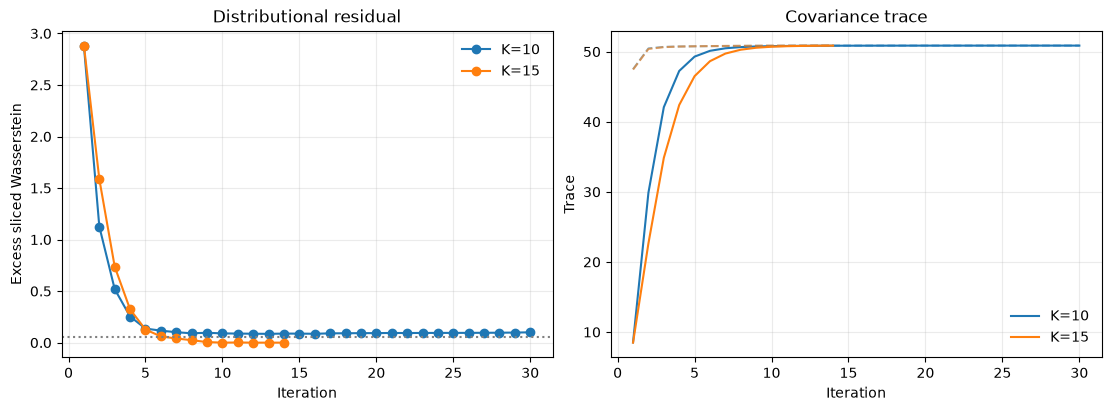

K=10 | excess residual=0.1001 | trace=50.864 | mean=[-0.5015 -0.2912]
K=15 | excess residual=0.0000 | trace=50.857 | mean=[-0.5022 -0.2926]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for n_components, (_, run_history, _) in results.items():
    iterations = [row['iteration'] for row in run_history]
    axes[0].plot(iterations, [row['excess_residual'] for row in run_history],
                 marker='o', label=f'K={n_components}')
    line, = axes[1].plot(iterations, [row['trace'] for row in run_history],
                         label=f'K={n_components}')
    axes[1].plot(iterations, [row['mapped_trace'] for row in run_history],
                 color=line.get_color(), linestyle='--', alpha=0.6)
axes[0].axhline(RESIDUAL_TOLERANCE, color='0.5', linestyle=':')
axes[0].set(title='Distributional residual', xlabel='Iteration', ylabel='Excess sliced Wasserstein')
axes[1].set(title='Covariance trace', xlabel='Iteration', ylabel='Trace')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
plt.show()

for n_components, (fit, run_history, _) in results.items():
    mean, covariance = gmm_moments(fit)
    final = run_history[-1]
    print(f'K={n_components:2d} | excess residual={final["excess_residual"]:.4f} ' 
          f'| trace={np.trace(covariance):.3f} | mean={mean}')

## Fitted prior object

The prior is represented by `mixture.weights`, `mixture.means`, and `mixture.covariances`. Here $z\in\mathbb{R}^2$ gives coordinates of the zero-mean 3D log-belief vector $\ell=Bz\in H$. Therefore each $\mu_k$ and $\Sigma_k$ also lives in this 2D coordinate system. Rotating the basis rotates these parameters but not the underlying distribution on $H$.

In [5]:
mean, covariance = gmm_moments(mixture)
print('weights:')
print(mixture.weights)
print('means:')
print(mixture.means)
print('covariances:')
print(mixture.covariances)
print('marginal mean:', mean)
print('marginal covariance:')
print(covariance)

weights:
[0.0375 0.058  0.0491 0.043  0.0459 0.061  0.0889 0.0779 0.1116 0.0891
 0.1197 0.0971 0.0276 0.0358 0.0577]
means:
[[  0.8772   0.4998]
 [ -0.5474  -0.3927]
 [  1.1538   0.0004]
 [ -1.8665   0.218 ]
 [ -0.5617  -1.9557]
 [  0.5952   1.0021]
 [ -3.5092   0.8481]
 [ -1.2254  -2.7523]
 [  2.6357   1.0344]
 [ -6.8779   1.4254]
 [  3.4756   2.1695]
 [ -2.0372  -6.1076]
 [-13.6754   2.7206]
 [ -3.6228 -11.5198]
 [  9.0969   5.1622]]
covariances:
[[[  0.0102   0.    ]
  [  0.       0.0102]]

 [[  0.2024  -0.338 ]
  [ -0.338    0.605 ]]

 [[  1.1286   1.1385]
  [  1.1385   1.2921]]

 [[  0.7199  -0.7168]
  [ -0.7168   1.3539]]

 [[  0.5242  -0.2936]
  [ -0.2936   2.3717]]

 [[  3.0243   0.7381]
  [  0.7381   0.2691]]

 [[  4.6358  -1.1793]
  [ -1.1793   1.917 ]]

 [[  1.0864   0.3202]
  [  0.3202   7.3565]]

 [[  9.0092   7.2635]
  [  7.2635   8.0458]]

 [[ 17.7323  -3.6756]
  [ -3.6756   4.9144]]

 [[ 21.834    9.7194]
  [  9.7194   5.6858]]

 [[  5.2609   4.1803]
  [  4.1803  16.001

## Prior in log-belief space

The density is analytic everywhere on the log-belief plane. The figures use symmetric display coordinates: horizontal position contrasts Sickness 1 with Sickness 2, while vertical position contrasts Healthy with the two sickness states. The finite square is only the plotting window, and values below $10^{-6}$ of the maximum share the palest color. The slices use these state-aligned directions rather than the arbitrary $z_1,z_2$ axes.

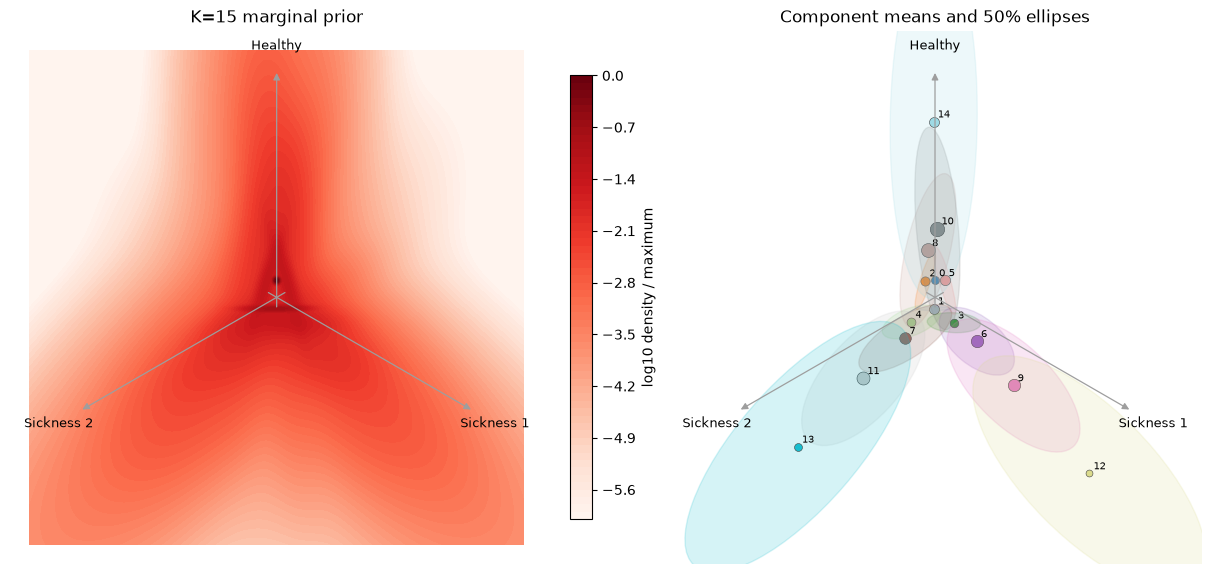

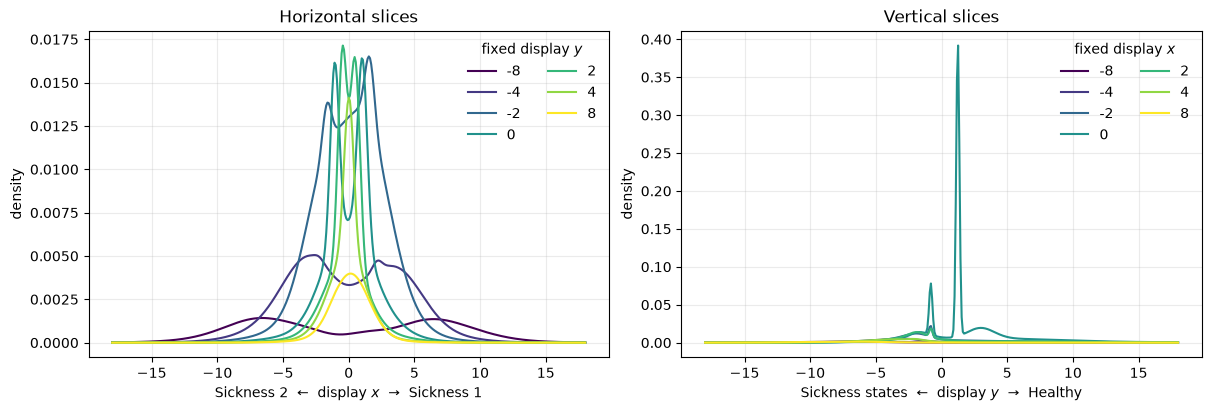

In [6]:
basis = default_basis()
frame = simplex_frame()
display_matrix = basis.T @ frame
display_to_z = np.linalg.inv(display_matrix)
axis = np.linspace(-LOG_LIMIT, LOG_LIMIT, 401)
display_x, display_y = np.meshgrid(axis, axis, indexing='xy')
display_points = np.column_stack([display_x.ravel(), display_y.ravel()])
points = display_points @ display_to_z
density = np.exp(gmm_logpdf(points, mixture)).reshape(display_x.shape)
log_relative = np.log10(np.maximum(density / density.max(), 1e-8))
density_cmap = plt.colormaps['Reds']
levels = np.linspace(-6, 0, 61)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
image = axes[0].contourf(display_x, display_y, np.maximum(log_relative, levels[0]),
                         levels=levels, cmap=density_cmap)
component_means = mixture.means @ display_matrix
component_covariances = np.array([
    display_matrix.T @ covariance @ display_matrix
    for covariance in mixture.covariances
])
colors = plt.cm.tab20(np.linspace(0, 1, len(mixture.weights)))
radius_50 = np.sqrt(2 * np.log(2))
for k, (weight, mean_k, covariance_k, color) in enumerate(zip(
        mixture.weights, component_means, component_covariances, colors)):
    values, vectors = np.linalg.eigh(covariance_k)
    order = np.argsort(values)[::-1]
    values, vectors = values[order], vectors[:, order]
    angle = np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0]))
    width, height = 2 * radius_50 * np.sqrt(values)
    axes[1].add_patch(Ellipse(mean_k, width, height, angle=angle,
                              facecolor=color, edgecolor=color, alpha=0.18))
    axes[1].scatter(*mean_k, s=900 * weight, color=color, edgecolor='0.25', lw=0.4)
    axes[1].annotate(str(k), mean_k, xytext=(3, 3), textcoords='offset points', fontsize=7)
for ax, title in zip(axes, [
        f'K={PLOT_COMPONENTS} marginal prior',
        'Component means and 50% ellipses']):
    for state, direction in zip(STATES, frame):
        ax.annotate('', xy=0.92 * LOG_LIMIT * direction, xytext=-0.05 * LOG_LIMIT * direction,
                    arrowprops=dict(arrowstyle='-|>', color='0.62', lw=0.9))
        ax.text(*(1.02 * LOG_LIMIT * direction), state, ha='center', va='center', fontsize=9)
    ax.set_title(title)
    ax.set_xlim(-1.08 * LOG_LIMIT, 1.08 * LOG_LIMIT)
    ax.set_ylim(-1.08 * LOG_LIMIT, 1.08 * LOG_LIMIT)
    ax.set_aspect('equal')
    ax.axis('off')
fig.colorbar(image, ax=axes[0], shrink=0.75, label='log10 density / maximum')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(SLICE_VALUES)))
density_scale = 1 / abs(np.linalg.det(display_matrix))
for value, color in zip(SLICE_VALUES, colors):
    horizontal = np.column_stack([axis, np.full_like(axis, value)]) @ display_to_z
    vertical = np.column_stack([np.full_like(axis, value), axis]) @ display_to_z
    axes[0].plot(axis, density_scale * np.exp(gmm_logpdf(horizontal, mixture)),
                 color=color, label=f'{value:g}')
    axes[1].plot(axis, density_scale * np.exp(gmm_logpdf(vertical, mixture)),
                 color=color, label=f'{value:g}')
axes[0].set(title='Horizontal slices', xlabel='Sickness 2  ←  display $x$  →  Sickness 1',
            ylabel='density')
axes[1].set(title='Vertical slices', xlabel='Sickness states  ←  display $y$  →  Healthy',
            ylabel='density')
axes[0].legend(title='fixed display $y$', frameon=False, ncol=2)
axes[1].legend(title='fixed display $x$', frameon=False, ncol=2)
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

## State-conditioned priors

Each panel fits a $K$-component GMM to the corresponding `mapped_by_state` distribution. The fourth panel is their equal-weight average, with $3K$ total components. These are diagnostic fits after the current marginal solver; they are not fed back into its fixed-point iteration.

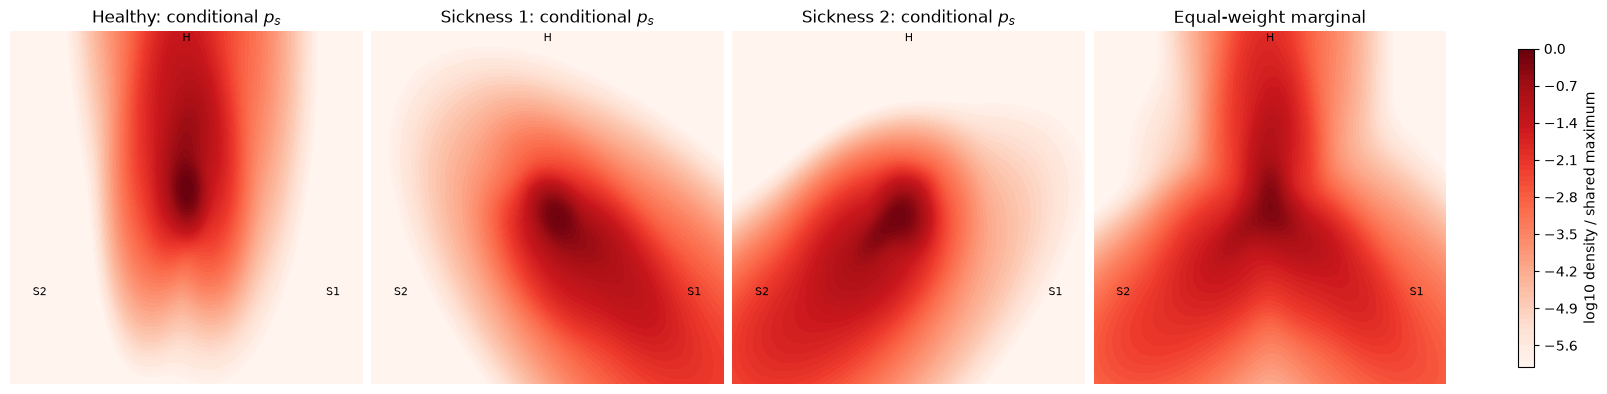

In [7]:
conditional_mixtures = [
    fit_gmm(mapped_by_state[state], CONDITIONAL_COMPONENTS,
            min_variance=MIN_STD**2, max_iterations=EM_MAX_ITERATIONS,
            seed=RANDOM_SEED + state)[0]
    for state in range(3)
]
conditional_marginal = combine_gmms(conditional_mixtures)
panel_mixtures = conditional_mixtures + [conditional_marginal]
panel_titles = [f'{state}: conditional $p_s$' for state in STATES] + ['Equal-weight marginal']
panel_density = np.array([
    np.exp(gmm_logpdf(points, fit)).reshape(display_x.shape)
    for fit in panel_mixtures
])
panel_log_relative = np.log10(np.maximum(panel_density / panel_density.max(), 1e-8))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)
for ax, title, values in zip(axes, panel_titles, panel_log_relative):
    image = ax.contourf(display_x, display_y, np.maximum(values, levels[0]),
                        levels=levels, cmap=density_cmap)
    for label, direction in zip(['H', 'S1', 'S2'], frame):
        ax.text(*(0.96 * LOG_LIMIT * direction), label, ha='center', va='center', fontsize=8)
    ax.set_title(title)
    ax.set_xlim(-LOG_LIMIT, LOG_LIMIT)
    ax.set_ylim(-LOG_LIMIT, LOG_LIMIT)
    ax.set_aspect('equal')
    ax.axis('off')
fig.colorbar(image, ax=axes, shrink=0.72, label='log10 density / shared maximum')
plt.show()

## Prior in probability space

This integrates the fitted GMM into equal-area simplex bins using fixed low-discrepancy points. It displays probability mass directly, without a sample cloud or KDE smoothing.

simplex histogram mass: 1.0000000000000737


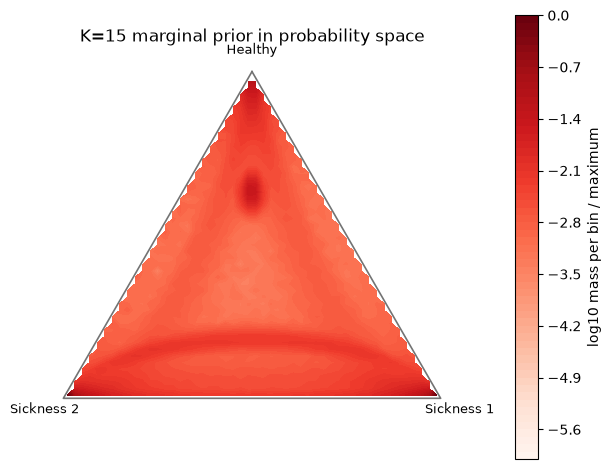

In [8]:
simplex_mass, x_edges, y_edges = simplex_histogram(
    mixture, n_bins=SIMPLEX_BINS, qmc_power=SIMPLEX_QMC_POWER, basis=basis,
)
print('simplex histogram mass:', simplex_mass.sum())
x = 0.5 * (x_edges[:-1] + x_edges[1:])
y = 0.5 * (y_edges[:-1] + y_edges[1:])
X, Y = np.meshgrid(x, y, indexing='xy')
healthy = (2 * Y + 1) / 3
sickness_1 = (1 - healthy) / 2 + X / np.sqrt(3)
inside = (healthy > 0) & (sickness_1 > 0) & (healthy + sickness_1 < 1)
relative = simplex_mass / simplex_mass.max()
log_relative = np.ma.masked_where(
    ~inside, np.log10(np.maximum(relative, 1e-8))
)
fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
image = ax.contourf(X, Y, np.maximum(log_relative, levels[0]),
                    levels=levels, cmap=density_cmap)
closed = np.vstack([frame, frame[0]])
ax.plot(closed[:, 0], closed[:, 1], color='0.45', lw=1.2)
for state, vertex in zip(STATES, frame):
    ax.text(*(1.10 * vertex), state, ha='center', va='center', fontsize=9)
ax.set_title(f'K={PLOT_COMPONENTS} marginal prior in probability space')
ax.set_xlim(-1.02, 1.02)
ax.set_ylim(-0.62, 1.10)
ax.set_aspect('equal')
ax.axis('off')
fig.colorbar(image, ax=ax, shrink=0.75, label='log10 mass per bin / maximum')
plt.show()

In [9]:
AGE_LAMBDA

0.9